# 🎵 Amazon Music Clustering

## Objective

The objective of this project is to group similar songs based on their audio features using K-Means clustering. Since the dataset does not contain predefined labels, an unsupervised machine learning approach is used to identify meaningful clusters. The quality of the clusters will be evaluated using Silhouette Score and Davies-Bouldin Index, and the results will be visualized using Principal Component Analysis (PCA).

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA


# Load the dataset
file_path = "../data/raw/single_genre_artists.csv"

original_df = pd.read_csv(file_path)

# Create a separate dataframe for clustering
df = original_df.copy()

# Display basic information
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())
# Display the first five rows
df.head()
df.columns
# Audio features selected for clustering
features = [
    'duration_ms',
    'danceability',
    'energy',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

X = df[features].copy()

print("Selected features:")
print(features)

print("\nFeature matrix shape:", X.shape)

X = df[features]

# Display the first five rows
X.head()
# Save the cleaned dataset
X.to_csv("../data/processed/cleaned_music.csv", index=False)

print("Processed dataset saved successfully!")





Dataset Shape: (95837, 23)

Column Names:
['id_songs', 'name_song', 'popularity_songs', 'duration_ms', 'explicit', 'id_artists', 'release_date', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'followers', 'genres', 'name_artists', 'popularity_artists']

Data Types:
id_songs                  str
name_song                 str
popularity_songs        int64
duration_ms             int64
explicit                int64
id_artists                str
release_date              str
danceability          float64
energy                float64
key                     int64
loudness              float64
mode                    int64
speechiness           float64
acousticness          float64
instrumentalness      float64
liveness              float64
valence               float64
tempo                 float64
time_signature          int64
followers             float64
genres                    s

Missing values in selected features:
duration_ms         0
danceability        0
energy              0
loudness            0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
dtype: int64

Missing values after handling:
duration_ms         0
danceability        0
energy              0
loudness            0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
dtype: int64
Scaled data shape: (95837, 10)


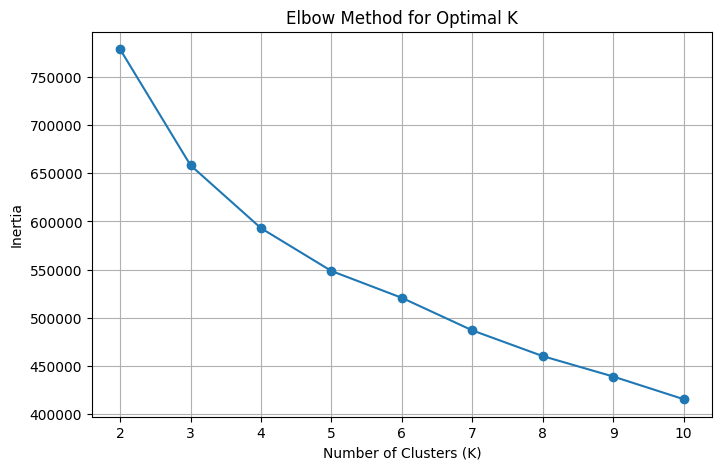

In [3]:
# Check for missing values in selected features
print("Missing values in selected features:")
print(X.isnull().sum())

# If missing values exist, fill numerical values with their median
if X.isnull().sum().sum() > 0:
    X = X.fillna(X.median())

print("\nMissing values after handling:")
print(X.isnull().sum())
# Standardize the features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)
scaled_df = pd.DataFrame(
    X_scaled,
    columns=features
)

scaled_df.head()
# Store inertia values
# Elbow Method
inertia = []

k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia.append(kmeans.inertia_)


# Plot the Elbow Curve
plt.figure(figsize=(8, 5))

plt.plot(k_values, inertia, marker='o')

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")

plt.xticks(k_values)
plt.grid(True)

plt.show()

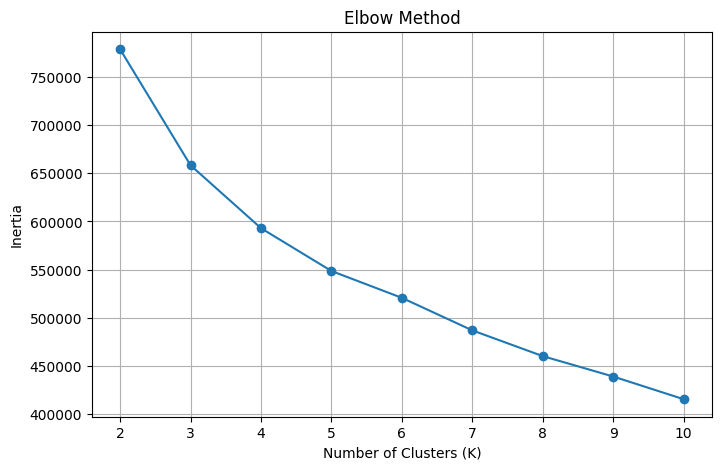

In [4]:
# Plot the Elbow Curve

plt.figure(figsize=(8,5))

plt.plot(k_values, inertia, marker='o')

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.grid(True)

plt.show()


In [6]:
# Final K-Means model
optimal_k = 5

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

# Add cluster labels to the clustering dataframe
df['Cluster'] = clusters

print("K-Means clustering completed.")
print("\nCluster counts:")
print(df['Cluster'].value_counts().sort_index())





K-Means clustering completed.

Cluster counts:
Cluster
0    30373
1     7527
2    12273
3    24584
4    21080
Name: count, dtype: int64


In [7]:
# Add cluster labels to the original dataframe
df['Cluster'] = clusters
# Display the first five rows
df.head()

,id_songs,name_song,popularity_songs,duration_ms,explicit,id_artists,release_date,danceability,energy,key,...,instrumentalness,liveness,valence,tempo,time_signature,followers,genres,name_artists,popularity_artists,Cluster
0,0IA0Hju8CAgYfV1hwhidBH,La Java,0,161427,0,4AxgXfD7ISvJSTObqm4aIE,1922,0.563,0.184,4,...,0.000016,0.325,0.654,133.088,3,5078.0,['vintage chanson'],Mistinguett,22,3
1,1b8HZQCqcqwbzlA1jRTp6E,En Douce,0,223440,0,4AxgXfD7ISvJSTObqm4aIE,1922,0.427,0.180,10,...,0.000000,0.128,0.431,78.459,3,5078.0,['vintage chanson'],Mistinguett,22,3
2,5d5gQxHwYovxR5pqETOIAa,J'en Ai Marre,0,208267,0,4AxgXfD7ISvJSTObqm4aIE,1922,0.511,0.206,0,...,0.000000,0.418,0.481,70.443,4,5078.0,['vintage chanson'],Mistinguett,22,3
3,1EO65UEEPfy7CR0NK2sDxy,Ils n'ont pas ca,0,161933,0,4AxgXfD7ISvJSTObqm4aIE,1924,0.676,0.467,9,...,0.000000,0.219,0.726,129.775,4,5078.0,['vintage chanson'],Mistinguett,22,3
4,6a58gXSgqbIsXUhVZ6ZJqe,La belote,0,167973,0,4AxgXfD7ISvJSTObqm4aIE,1924,0.650,0.298,9,...,0.000000,0.373,0.844,75.950,4,5078.0,['vintage chanson'],Mistinguett,22,3


In [8]:
# Silhouette Score
silhouette = silhouette_score(
    X_scaled,
    clusters
)

# Davies-Bouldin Index
db_index = davies_bouldin_score(
    X_scaled,
    clusters
)

print(f"Silhouette Score: {silhouette:.4f}")
print(f"Davies-Bouldin Index: {db_index:.4f}")

Silhouette Score: 0.1864
Davies-Bouldin Index: 1.6888


In [9]:
# PCA for 2D visualization

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print(
    f"\nTotal Variance Explained by 2 Components: "
    f"{pca.explained_variance_ratio_.sum():.2%}"
)
# Create dataframe for PCA visualization

pca_df = pd.DataFrame(
    X_pca,
    columns=['PCA1', 'PCA2']
)

pca_df['Cluster'] = clusters

pca_df.head()

Explained Variance Ratio:
[0.27079553 0.18821441]

Total Variance Explained by 2 Components: 45.90%


,PCA1,PCA2,Cluster
0,-1.676304,0.291571,3
1,-2.639968,-0.472803,3
2,-2.537328,0.474464,3
3,-0.677418,0.709757,3
4,-1.480657,1.426716,3


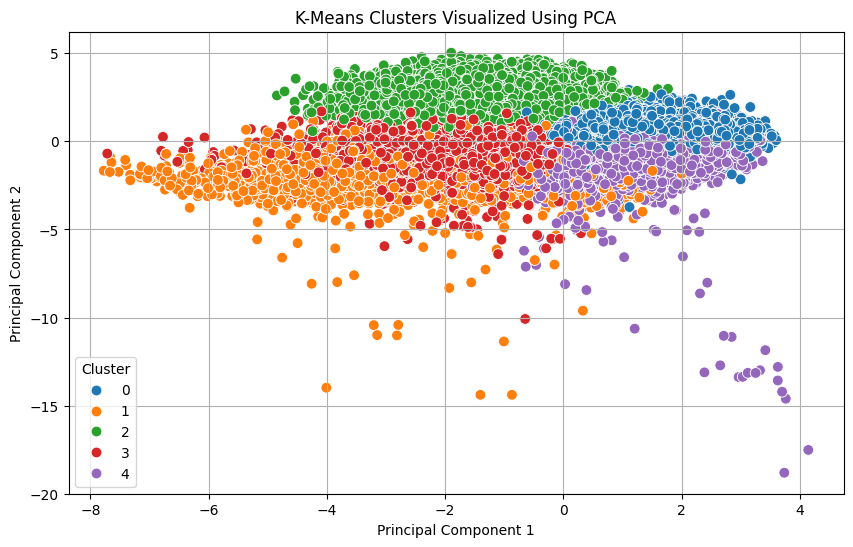

Cluster
0    30373
1     7527
2    12273
3    24584
4    21080
Name: count, dtype: int64


In [6]:
# Visualize clusters using PCA

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x='PCA1',
    y='PCA2',
    hue='Cluster',
    palette='tab10',
    s=60
)

plt.title("K-Means Clusters Visualized Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.grid(True)

plt.show()
# Count songs in each cluster
cluster_counts = df['Cluster'].value_counts().sort_index()

print(cluster_counts)



In [7]:
# Analyze cluster sizes

cluster_counts = (
    df['Cluster']
    .value_counts()
    .sort_index()
)

print("Number of songs in each cluster:")
print(cluster_counts)

Number of songs in each cluster:
Cluster
0    30373
1     7527
2    12273
3    24584
4    21080
Name: count, dtype: int64


In [8]:
# Calculate average audio features for each cluster

cluster_summary = (
    df.groupby('Cluster')[features]
    .mean()
    .round(3)
)

cluster_summary

,duration_ms,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
Cluster,,,,,,,,,,
0,213629.944,0.707,0.672,-7.986,0.078,0.310,0.021,0.171,0.787,117.846
1,227500.962,0.484,0.400,-14.207,0.059,0.668,0.817,0.185,0.450,113.510
2,96210.790,0.664,0.466,-13.388,0.839,0.586,0.001,0.436,0.583,100.176
3,220935.668,0.504,0.313,-12.635,0.062,0.744,0.018,0.180,0.420,111.126
4,246252.002,0.502,0.712,-7.072,0.073,0.193,0.029,0.247,0.488,136.128


In [9]:
# Load the original dataset again
original_df = pd.read_csv("../data/raw/single_genre_artists.csv")
original_df["Cluster"] = clusters
# Display the top 5 most popular songs in each cluster

top_tracks = (
    df.sort_values(by="popularity_songs", ascending=False)
      .groupby("Cluster")
      .head(5)
)

top_tracks[
[
    "Cluster",
    "name_song",
    "name_artists",
    "popularity_songs"
    ]
]

,Cluster,name_song,name_artists,popularity_songs
35665,0,Astronaut In The Ocean,Masked Wolf,98
35398,0,WITHOUT YOU,The Kid LAROI,94
35422,0,Hecha Pa' Mi,Boza,92
35241,0,What You Know Bout Love,Pop Smoke,91
35532,0,911,Sech,91
35233,3,Arcade,Duncan Laurence,89
35436,4,Put Your Records On,Ritt Momney,87
35239,4,Dior,Pop Smoke,86
32855,4,Hayloft,Mother Mother,86
35506,4,Girls Like Us,Zoe Wees,86


In [26]:
## Step 10: Interpret Cluster Characteristics # Calculate the mean of each feature for every cluster
cluster_summary = df.groupby('Cluster')[features].mean()

cluster_summary


,duration_ms,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
Cluster,,,,,,,,,,
0,213629.943898,0.706962,0.671949,-7.986034,0.078149,0.309603,0.021395,0.171255,0.786520,117.845522
1,227500.961738,0.484072,0.400033,-14.207328,0.059369,0.668444,0.817177,0.185157,0.449815,113.510101
2,96210.790434,0.664406,0.466487,-13.387732,0.838939,0.586096,0.000879,0.435634,0.583226,100.176056
3,220935.668443,0.503925,0.313460,-12.634777,0.062285,0.743712,0.018421,0.179605,0.419779,111.125521
4,246252.002182,0.502056,0.711780,-7.072090,0.072693,0.193385,0.028849,0.246591,0.487895,136.128338


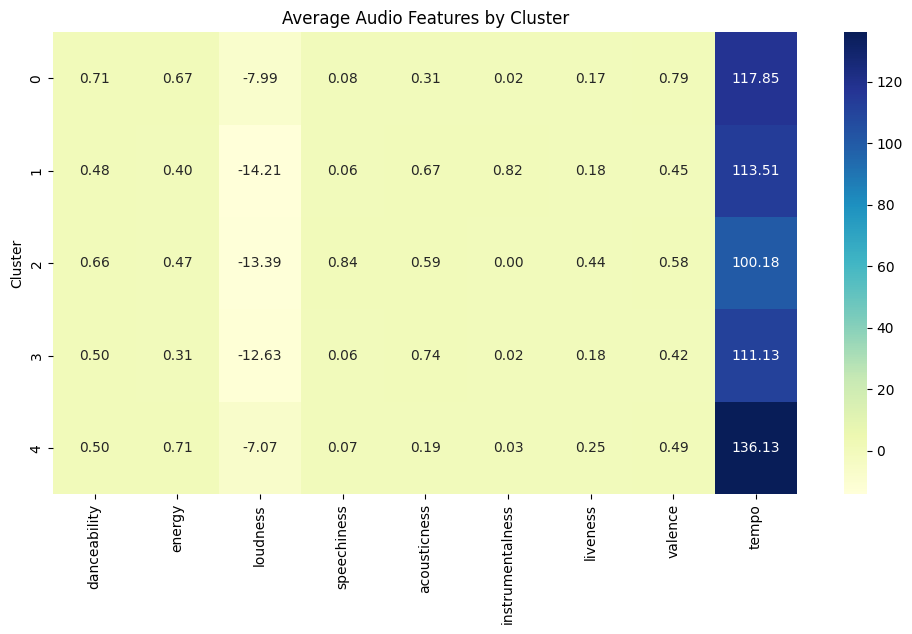

In [10]:
cluster_summary_plot = cluster_summary.drop(columns=['duration_ms'])

plt.figure(figsize=(12,6))

sns.heatmap(
    cluster_summary_plot,
    annot=True,
    cmap="YlGnBu",
    fmt=".2f"
)

plt.title("Average Audio Features by Cluster")
plt.show()

In [11]:
original_df.to_csv(
    "../data/processed/clustered_music.csv",
    index=False
)

print("Final clustered dataset exported successfully!")

Final clustered dataset exported successfully!
